## 1. Preparar o ambiente

Importar as bibliotecas necessárias, conectar ao Google Drive quando estiver no Colab e localizar as pastas do projeto.

In [3]:
#Campo de importações
import pandas as pd
import numpy as np
import pathlib as path
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import os
from pathlib import Path

# Procura o diretório raiz local do projeto.
def encontrar_pasta_projeto():
    candidatos = [Path.cwd().resolve(), *Path.cwd().resolve().parents]

    for candidato in candidatos:
        if (candidato / "dados_brutos").is_dir():
            return candidato

    # Caminho usado no Google Colab após montar o Google Drive.
    candidato_colab = Path("/content/drive/MyDrive/Projeto_Analise_Olist")
    if candidato_colab.is_dir():
        return candidato_colab

    raise FileNotFoundError(
        "Não foi encontrada a pasta 'dados_brutos'. "
        "Execute o notebook na raiz do projeto ou monte o Google Drive no Colab."
    )

PASTA_PROJETO = encontrar_pasta_projeto()

# Diretórios do projeto
PASTA_DADOS = PASTA_PROJETO / "dados_brutos"
PASTA_TRATADOS = PASTA_PROJETO / "dados_tratados"
PASTA_RELATORIOS = PASTA_PROJETO / "relatorios"

PASTA_TRATADOS.mkdir(parents=True, exist_ok=True)
PASTA_RELATORIOS.mkdir(parents=True, exist_ok=True)

print("Diretório do projeto:", PASTA_PROJETO)
print("Dados brutos:", PASTA_DADOS.is_dir())
print("Dados tratados:", PASTA_TRATADOS.is_dir())
print("Relatórios:", PASTA_RELATORIOS.is_dir())


Diretório do projeto: C:\Users\r0663\OneDrive\Documentos\GitHub\Projeto-Analise-Exploratoria-Olist-Vendedores
Dados brutos: True
Dados tratados: True
Relatórios: True


## 2. Conhecer as bases

Carregar os arquivos CSV e explorar sua estrutura, qualidade e características antes da preparação dos dados.

In [5]:

import pandas as pd
import os

# Arquivos que serão utilizados na análise
arquivos = {
    'orders': 'olist_orders_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'customers': 'olist_customers_dataset.csv'
}

# Dicionário para armazenar os DataFrames
dados = {}

for nome, arquivo in arquivos.items():

    caminho = os.path.join(PASTA_DADOS, arquivo)

    if os.path.exists(caminho):

        dados[nome] = pd.read_csv(
            caminho,
            low_memory=False
        )

        print(f'{nome}: {dados[nome].shape}')

    else:
        print(f'ARQUIVO NÃO ENCONTRADO: {arquivo}')

print('\nCarregamento finalizado!')


orders: (99441, 8)
items: (112650, 7)
products: (32951, 9)
sellers: (3095, 4)
reviews: (99224, 7)
customers: (99441, 5)

Carregamento finalizado!


In [6]:

#VALORES AUSENTES

relatorio_ausentes = []

for nome, df in dados.items():

    for coluna in df.columns:

        quantidade = df[coluna].isna().sum()

        percentual = (quantidade / len(df)) * 100

        relatorio_ausentes.append({
            'Base': nome,
            'Coluna': coluna,
            'Valores_Ausentes': quantidade,
            'Percentual_Ausente': round(percentual, 2)
        })

relatorio_ausentes = pd.DataFrame(relatorio_ausentes)

# Parte que mostra somente colunas que possuem valores ausentes, sem precisar usar o restante.
relatorio_ausentes = relatorio_ausentes[
    relatorio_ausentes['Valores_Ausentes'] > 0
].sort_values(
    by='Percentual_Ausente',
    ascending=False
)

display(relatorio_ausentes)


,Base,Coluna,Valores_Ausentes,Percentual_Ausente
31,reviews,review_comment_title,87656,88.34
32,reviews,review_comment_message,58247,58.70
6,orders,order_delivered_customer_date,2965,2.98
17,products,product_name_lenght,610,1.85
16,products,product_category_name,610,1.85
18,products,product_description_lenght,610,1.85
19,products,product_photos_qty,610,1.85
5,orders,order_delivered_carrier_date,1783,1.79
4,orders,order_approved_at,160,0.16
21,products,product_length_cm,2,0.01


In [7]:
#Parte para saber as duplicatas dos dados
for nome, df in dados.items():

    duplicatas = df.duplicated().sum()

    print(f'\nBase: {nome}')
    print(f'Total de registros: {len(df)}')
    print(f'Duplicatas completas: {duplicatas}')



Base: orders
Total de registros: 99441
Duplicatas completas: 0

Base: items
Total de registros: 112650
Duplicatas completas: 0

Base: products
Total de registros: 32951
Duplicatas completas: 0

Base: sellers
Total de registros: 3095
Duplicatas completas: 0

Base: reviews
Total de registros: 99224
Duplicatas completas: 0

Base: customers
Total de registros: 99441
Duplicatas completas: 0


In [8]:
#Verificação das duplicatas nas chaves primarias, mesmo contendo colunas diferentes

chaves = {
    'orders': ['order_id'],
    'items': ['order_id', 'order_item_id'],
    'products': ['product_id'],
    'sellers': ['seller_id'],
    'reviews': ['review_id'],
    'customers': ['customer_id']
}

for nome, colunas in chaves.items():

    df = dados[nome]

    duplicados = df.duplicated(subset=colunas).sum()

    nulos = df[colunas].isna().sum().sum()

    print(f'\nBase: {nome}')
    print(f'Chave analisada: {colunas}')
    print(f'Registros com chave duplicada: {duplicados}')
    print(f'Valores nulos nas chaves: {nulos}')



Base: orders
Chave analisada: ['order_id']
Registros com chave duplicada: 0
Valores nulos nas chaves: 0



Base: items
Chave analisada: ['order_id', 'order_item_id']
Registros com chave duplicada: 0
Valores nulos nas chaves: 0

Base: products
Chave analisada: ['product_id']
Registros com chave duplicada: 0
Valores nulos nas chaves: 0

Base: sellers
Chave analisada: ['seller_id']
Registros com chave duplicada: 0
Valores nulos nas chaves: 0

Base: reviews
Chave analisada: ['review_id']
Registros com chave duplicada: 814
Valores nulos nas chaves: 0

Base: customers
Chave analisada: ['customer_id']
Registros com chave duplicada: 0
Valores nulos nas chaves: 0


In [9]:
#Parte para identificar se existe produtos sem despacho

# DIAGNÓSTICO 4 - STATUS DOS PEDIDOS SEM DESPACHO

orders = dados['orders']

sem_despacho = orders[
    orders['order_delivered_carrier_date'].isna()
]

print('Total de pedidos sem data de despacho:')
print(len(sem_despacho))

print('\nStatus desses pedidos:')
display(
    sem_despacho['order_status']
    .value_counts(dropna=False)
    .to_frame('Quantidade')
)

print('\nStatus de todos os pedidos:')
display(
    orders['order_status']
    .value_counts(dropna=False)
    .to_frame('Quantidade')
)



Total de pedidos sem data de despacho:
1783

Status desses pedidos:


,Quantidade
order_status,
unavailable,609
canceled,550
invoiced,314
processing,301
created,5
approved,2
delivered,2



Status de todos os pedidos:


,Quantidade
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [10]:
#Parte para identificar se exite algum produto com campos não preenchidos

# DIAGNÓSTICO 5 - PRODUTOS COM INFORMAÇÕES AUSENTES

products = dados['products']

colunas_verificar = [
    'product_name_lenght',
    'product_category_name',
    'product_description_lenght',
    'product_photos_qty',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

produtos_incompletos = products[
    products[colunas_verificar].isna().any(axis=1)
]

print('Total de produtos com alguma informação ausente:')
print(len(produtos_incompletos))

display(produtos_incompletos.head(15))


Total de produtos com alguma informação ausente:
611


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [11]:
#Parte para descobrir se o se o mesmo review_id está associado a pedidos diferentes

# INVESTIGAÇÃO - REVIEW_ID REPETIDOS

reviews = dados['reviews']

# Quantidade de IDs repetidos
ids_repetidos = reviews[
    reviews.duplicated(subset=['review_id'], keep=False)
].sort_values('review_id')

print("Total de linhas envolvidas em IDs repetidos:",
      len(ids_repetidos))

print("Quantidade de IDs distintos repetidos:",
      ids_repetidos['review_id'].nunique())

# Mostrar exemplos para entender as diferenças
display(ids_repetidos.head(20))

# Verificar quantas vezes cada ID aparece
frequencia = (
    ids_repetidos['review_id']
    .value_counts()
    .value_counts()
    .sort_index()
)

print("\nQuantidade de IDs conforme número de ocorrências:")
display(frequencia.to_frame('Quantidade de IDs'))


Total de linhas envolvidas em IDs repetidos: 1603
Quantidade de IDs distintos repetidos: 789


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44



Quantidade de IDs conforme número de ocorrências:


,Quantidade de IDs
count,
2,764
3,25


In [12]:

# Parte para descobrir os pedidos despachados sem data

orders = dados['orders']

entregues_sem_despacho = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_carrier_date'].isna())
]

print("Pedidos entregues sem data de despacho:")
display(entregues_sem_despacho)

print("\nInformações dos pedidos:")
display(
    entregues_sem_despacho[
        [
            'order_id',
            'order_status',
            'order_purchase_timestamp',
            'order_approved_at',
            'order_delivered_carrier_date',
            'order_delivered_customer_date',
            'order_estimated_delivery_date'
        ]
    ]
)


Pedidos entregues sem data de despacho:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
73222,2aa91108853cecb43c84a5dc5b277475,afeb16c7f46396c0ed54acb45ccaaa40,delivered,2017-09-29 08:52:58,2017-09-29 09:07:16,NaN,2017-11-20 19:44:47,2017-11-14 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00



Informações dos pedidos:


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
73222,2aa91108853cecb43c84a5dc5b277475,delivered,2017-09-29 08:52:58,2017-09-29 09:07:16,NaN,2017-11-20 19:44:47,2017-11-14 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00


In [13]:

# Parte para identificar se existe produtos com mais de um campo incompleto

products = dados['products']

colunas_descritivas = [
    'product_category_name',
    'product_name_lenght',
    'product_description_lenght',
    'product_photos_qty'
]

colunas_fisicas = [
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

print("Ausências nas informações descritivas:")
display(products[colunas_descritivas].isna().sum())

print("\nAusências nas informações físicas:")
display(products[colunas_fisicas].isna().sum())

# Mostrar produtos que possuem alguma informação física ausente
fisicos_incompletos = products[
    products[colunas_fisicas].isna().any(axis=1)
]

print("\nProdutos com informações físicas incompletas:")
display(fisicos_incompletos)


Ausências nas informações descritivas:


product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
dtype: int64


Ausências nas informações físicas:


product_weight_g     2
product_length_cm    2
product_height_cm    2
product_width_cm     2
dtype: int64


Produtos com informações físicas incompletas:


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:

# Parte para a verificação da base reviws para encontrar as duplicatas

reviews = dados['reviews']

resumo_reviews = (
    reviews.groupby('review_id')
    .agg(
        quantidade_linhas=('order_id', 'size'),
        pedidos_distintos=('order_id', 'nunique'),
        notas_distintas=('review_score', 'nunique'),
        comentarios_distintos=('review_comment_message',
                               lambda x: x.nunique(dropna=False)),
        datas_distintas=('review_creation_date',
                         lambda x: x.nunique(dropna=False))
    )
    .reset_index()
)

repetidos = resumo_reviews[
    resumo_reviews['quantidade_linhas'] > 1
]

print("IDs repetidos com pedidos diferentes:")
print(
    (repetidos['pedidos_distintos'] > 1).sum()
)

print("\nIDs repetidos com notas diferentes:")
print(
    (repetidos['notas_distintas'] > 1).sum()
)

print("\nIDs repetidos com comentários diferentes:")
print(
    (repetidos['comentarios_distintos'] > 1).sum()
)

print("\nIDs repetidos com datas diferentes:")
print(
    (repetidos['datas_distintas'] > 1).sum()
)

print("\nPedidos repetidos na tabela de avaliações:")
print(reviews.duplicated(subset=['order_id']).sum())

print("\nExemplos de grupos repetidos:")
display(repetidos.head(15))


IDs repetidos com pedidos diferentes:
789

IDs repetidos com notas diferentes:
0

IDs repetidos com comentários diferentes:
0

IDs repetidos com datas diferentes:
0

Pedidos repetidos na tabela de avaliações:
551

Exemplos de grupos repetidos:


,review_id,quantidade_linhas,pedidos_distintos,notas_distintas,comentarios_distintos,datas_distintas
31,00130cbe1f9d422698c812ed8ded1919,2,2,1,1,1
425,0115633a9c298b6a98bcbe4eee75345f,2,2,1,1,1
568,0174caf0ee5964646040cd94e15ac95e,2,2,1,1,1
574,017808d29fd1f942d97e50184dfb4c13,2,2,1,1,1
884,0254bd905dc677a6078990aad3331a36,2,2,1,1,1
961,0288d42bef3dfe36930740c9588a570f,2,2,1,1,1
1000,02aa7f5f75e964e3c7efa59a1f515281,2,2,1,1,1
1225,034528cb00b6bc981847acafbdf2ae0b,2,2,1,1,1
1364,03a6a25db577d0689440933055111897,2,2,1,1,1
1674,0467560f511c516ddaa54a60edb0c291,2,2,1,1,1


In [15]:

#Parte para verificar se existe algum pedido com a mesma avaliação

reviews = dados['reviews']

# Quantidade de avaliações distintas por pedido
avaliacoes_por_pedido = (
    reviews.groupby('order_id')['review_id']
    .nunique()
)

print("Pedidos associados a mais de um review_id:")
print((avaliacoes_por_pedido > 1).sum())

print("\nPedidos associados a exatamente um review_id:")
print((avaliacoes_por_pedido == 1).sum())

print("\nMaior quantidade de avaliações por pedido:")
print(avaliacoes_por_pedido.max())

# Verificar se existem linhas exatamente iguais
print("\nDuplicatas completas:")
print(reviews.duplicated().sum())


Pedidos associados a mais de um review_id:
547

Pedidos associados a exatamente um review_id:
98126

Maior quantidade de avaliações por pedido:
3

Duplicatas completas:
0


## Limpeza dos dados

In [16]:
# Fazer uma cópia para realizar a limpeza e  preservar os DataFrames verdadeiros

dados_limpos = {
    nome: df.copy()
    for nome, df in dados.items()
}

print("Cópias criadas com sucesso!")

for nome, df in dados_limpos.items():
    print(f"{nome}: {df.shape}")

Cópias criadas com sucesso!
orders: (99441, 8)
items: (112650, 7)
products: (32951, 9)
sellers: (3095, 4)
reviews: (99224, 7)
customers: (99441, 5)


In [17]:
# Parte para converter as colunas de datas para o formato datetime.
colunas_data = {
    'orders': [
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ],

    'items': [
        'shipping_limit_date'
    ],

    'reviews': [
        'review_creation_date',
        'review_answer_timestamp'
    ]
}

# Conversão das datas
for tabela, colunas in colunas_data.items():

    for coluna in colunas:

        if coluna in dados_limpos[tabela].columns:

            dados_limpos[tabela][coluna] = pd.to_datetime(
                dados_limpos[tabela][coluna],
                errors='coerce'
            )

print("Conversão de datas concluída!")

Conversão de datas concluída!


In [18]:
#Conferência de dados
for tabela, colunas in colunas_data.items():

    print(f"\n--- {tabela.upper()} ---")

    print(
        dados_limpos[tabela][colunas].dtypes
    )


--- ORDERS ---
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

--- ITEMS ---
shipping_limit_date    datetime64[ns]
dtype: object

--- REVIEWS ---
review_creation_date       datetime64[ns]
review_answer_timestamp    datetime64[ns]
dtype: object


In [19]:

#Parte para verificar se existe inconsistência cronológica
orders = dados_limpos['orders']


inconsistencias = {
    'Aprovação anterior à compra':
        orders['order_approved_at'] < orders['order_purchase_timestamp'],

    'Despacho anterior à aprovação':
        orders['order_delivered_carrier_date'] < orders['order_approved_at'],

    'Entrega anterior ao despacho':
        orders['order_delivered_customer_date'] < orders['order_delivered_carrier_date'],

    'Entrega anterior à compra':
        orders['order_delivered_customer_date'] < orders['order_purchase_timestamp']
}

for descricao, condicao in inconsistencias.items():

    quantidade = condicao.fillna(False).sum()

    print(f'{descricao}: {quantidade}')

Aprovação anterior à compra: 0
Despacho anterior à aprovação: 1359
Entrega anterior ao despacho: 23
Entrega anterior à compra: 0


In [20]:
# Parte para verificar o despacho antes da compra
orders = dados_limpos['orders']
items = dados_limpos['items']

itens_verificacao = items.merge(
    orders[['order_id', 'order_purchase_timestamp']],
    on='order_id',
    how='left'
)

prazo_invalido = (
    itens_verificacao['shipping_limit_date'] <
    itens_verificacao['order_purchase_timestamp']
)

print(
    "Itens com prazo de despacho anterior à compra:",
    prazo_invalido.fillna(False).sum()
)

Itens com prazo de despacho anterior à compra: 0


Verificação dos dados encontrados

In [21]:

#Identificar pedidos com despacho anterior à aprovação
orders = dados_limpos['orders']

despacho_antes_aprovacao = orders[
    orders['order_delivered_carrier_date'].notna() &
    orders['order_approved_at'].notna() &
    (
        orders['order_delivered_carrier_date'] <
        orders['order_approved_at']
    )
]

print("Total:", len(despacho_antes_aprovacao))

print("\nDistribuição por status:")
print(
    despacho_antes_aprovacao['order_status']
    .value_counts()
)

print("\nPrimeiros registros:")
display(
    despacho_antes_aprovacao[
        [
            'order_id',
            'order_status',
            'order_purchase_timestamp',
            'order_approved_at',
            'order_delivered_carrier_date'
        ]
    ].head(10)
)

Total: 1359

Distribuição por status:
order_status
delivered    1350
shipped         9
Name: count, dtype: int64

Primeiros registros:


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date
15,dcb36b511fcac050b97cd5c05de84dc3,delivered,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-11 14:54:00
64,688052146432ef8253587b930b01a06d,delivered,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14
199,58d4c4747ee059eeeb865b349b41f53a,delivered,2018-07-21 12:49:32,2018-07-26 23:31:53,2018-07-24 12:57:00
210,412fccb2b44a99b36714bca3fef8ad7b,delivered,2018-07-22 22:30:05,2018-07-23 12:31:53,2018-07-23 12:24:00
415,56a4ac10a4a8f2ba7693523bb439eede,delivered,2018-07-22 13:04:47,2018-07-27 23:31:09,2018-07-24 14:03:00
481,32e4fa9bb468884309b58b9348de70c3,delivered,2018-07-04 16:49:21,2018-07-05 16:33:06,2018-07-05 14:50:00
483,4df92d82d79c3b52c7138679fa9b07fc,delivered,2018-07-24 11:32:11,2018-07-29 23:30:52,2018-07-26 14:46:00
585,16e38caa92e342c7780f68832f832d4d,delivered,2018-05-07 01:09:09,2018-05-07 16:52:39,2018-05-07 15:09:00
615,b9afddbdcfadc9a87b41a83271c3e888,delivered,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00
817,6051e6d3da9a50b7325cbe9c81025062,delivered,2018-07-03 23:40:16,2018-07-05 16:31:26,2018-07-04 12:14:00


In [22]:
# Identificar pedidos com entrega anterior ao despacho
entrega_antes_despacho = orders[
    orders['order_delivered_customer_date'].notna() &
    orders['order_delivered_carrier_date'].notna() &
    (
        orders['order_delivered_customer_date'] <
        orders['order_delivered_carrier_date']
    )
]

print("Total:", len(entrega_antes_despacho))

print("\nDistribuição por status:")
print(
    entrega_antes_despacho['order_status']
    .value_counts()
)

print("\nRegistros encontrados:")
display(
    entrega_antes_despacho[
        [
            'order_id',
            'order_status',
            'order_purchase_timestamp',
            'order_approved_at',
            'order_delivered_carrier_date',
            'order_delivered_customer_date'
        ]
    ]
)

Total: 23

Distribuição por status:
order_status
delivered    23
Name: count, dtype: int64

Registros encontrados:


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-20 11:20:52,2017-07-21 06:43:14,2017-07-28 16:57:58,2017-07-25 19:32:56
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-02 20:58:43,2017-07-02 21:10:20,2017-07-07 17:22:41,2017-07-06 14:27:51
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-16 12:35:34,2017-07-18 06:03:50,2017-07-20 19:22:02,2017-07-19 14:13:28
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-07-20 20:58:05,2017-07-22 11:45:11,2017-08-01 18:23:30,2017-07-26 18:09:10
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-18 11:48:20,2017-07-18 12:03:29,2017-07-20 23:03:42,2017-07-20 18:52:41
21338,8c78d01de3a9009e23d6877a7cc9be20,delivered,2016-10-08 15:36:50,2016-10-08 18:13:44,2016-10-26 11:41:53,2016-10-25 17:51:46
22520,b27af682321527a6349f1761eb3f360c,delivered,2017-06-14 20:17:04,2017-06-14 20:30:08,2017-06-27 14:51:54,2017-06-26 15:45:35
25393,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-07 21:35:22,2017-08-08 21:45:15,2017-08-10 18:28:56,2017-08-10 18:05:38
25646,e37f11cae9985ca58f0b56f268720537,delivered,2017-07-26 11:46:34,2017-07-27 10:10:16,2017-08-01 18:17:47,2017-07-31 17:49:56
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-07-30 19:32:23,2017-07-30 19:45:09,2017-08-09 18:18:43,2017-08-01 21:13:01


In [23]:
# Diferença em horas entre aprovação e despacho
despacho_antes_aprovacao = despacho_antes_aprovacao.copy()

despacho_antes_aprovacao['diferenca_horas'] = (
    despacho_antes_aprovacao['order_approved_at'] -
    despacho_antes_aprovacao['order_delivered_carrier_date']
).dt.total_seconds() / 3600

print("Resumo da diferença em horas:")
print(
    despacho_antes_aprovacao['diferenca_horas'].describe()
)

Resumo da diferença em horas:
count    1359.000000
mean       24.751987
std       115.307793
min         0.005833
25%         1.415417
50%        17.167778
75%        25.956667
max      4109.256111
Name: diferenca_horas, dtype: float64


In [24]:
# Diferença em horas entre despacho e entrega
entrega_antes_despacho = entrega_antes_despacho.copy()

entrega_antes_despacho['diferenca_horas'] = (
    entrega_antes_despacho['order_delivered_carrier_date'] -
    entrega_antes_despacho['order_delivered_customer_date']
).dt.total_seconds() / 3600

print("Resumo da diferença em horas:")
print(
    entrega_antes_despacho['diferenca_horas'].describe()
)

Resumo da diferença em horas:
count     23.000000
mean      78.455133
std       89.308070
min        0.388333
25%       23.338333
50%       39.864444
75%      128.759028
max      386.308056
Name: diferenca_horas, dtype: float64


In [25]:
# Criar uma cópia para registrar as inconsistências

orders = dados_limpos['orders']


orders['inconsistencia_aprovacao_despacho'] = (
    orders['order_delivered_carrier_date'].notna() &
    orders['order_approved_at'].notna() &
    (
        orders['order_delivered_carrier_date'] <
        orders['order_approved_at']
    )
)

orders['inconsistencia_despacho_entrega'] = (
    orders['order_delivered_customer_date'].notna() &
    orders['order_delivered_carrier_date'].notna() &
    (
        orders['order_delivered_customer_date'] <
        orders['order_delivered_carrier_date']
    )
)

print("Inconsistências registradas:")

print(
    "Aprovação x despacho:",
    orders['inconsistencia_aprovacao_despacho'].sum()
)

print(
    "Despacho x entrega:",
    orders['inconsistencia_despacho_entrega'].sum()
)

Inconsistências registradas:
Aprovação x despacho: 1359
Despacho x entrega: 23


In [26]:
# Verificar valores únicos das colunas categóricas
for tabela, df in dados_limpos.items():

    colunas_categoricas = df.select_dtypes(
        include=['object']
    ).columns

    print(f"\n===== {tabela.upper()} =====")

    for coluna in colunas_categoricas:

        print(f"\n{coluna}:")
        print(df[coluna].nunique(), "valores únicos")


===== ORDERS =====

order_id:
99441 valores únicos

customer_id:
99441 valores únicos

order_status:
8 valores únicos

===== ITEMS =====

order_id:
98666 valores únicos

product_id:
32951 valores únicos

seller_id:
3095 valores únicos

===== PRODUCTS =====

product_id:
32951 valores únicos

product_category_name:
73 valores únicos

===== SELLERS =====

seller_id:
3095 valores únicos

seller_city:
611 valores únicos

seller_state:
23 valores únicos

===== REVIEWS =====

review_id:
98410 valores únicos

order_id:
98673 valores únicos

review_comment_title:
4527 valores únicos

review_comment_message:
36159 valores únicos

===== CUSTOMERS =====

customer_id:
99441 valores únicos

customer_unique_id:
96096 valores únicos

customer_city:
4119 valores únicos

customer_state:
27 valores únicos


In [27]:
# Colunas categóricas que precisam de investigação
colunas_verificacao = {
    'orders': ['order_status'],
    'products': ['product_category_name'],
    'sellers': ['seller_city', 'seller_state'],
    'customers': ['customer_city', 'customer_state']
}

for tabela, colunas in colunas_verificacao.items():

    print(f"\n========== {tabela.upper()} ==========")

    for coluna in colunas:

        serie = dados_limpos[tabela][coluna].dropna()

        # Verificar espaços no início ou final
        espacos = serie.apply(
            lambda x: x != x.strip()
        ).sum()

        # Verificar quantidade de valores em maiúsculas
        maiusculas = serie.apply(
            lambda x: x != x.lower()
        ).sum()

        print(f"\nColuna: {coluna}")
        print("Valores únicos:", serie.nunique())
        print("Registros com espaços extras:", espacos)
        print("Registros com letras maiúsculas:", maiusculas)


========== ORDERS ==========

Coluna: order_status
Valores únicos: 8
Registros com espaços extras: 0
Registros com letras maiúsculas: 0

========== PRODUCTS ==========

Coluna: product_category_name
Valores únicos: 73
Registros com espaços extras: 0
Registros com letras maiúsculas: 0

========== SELLERS ==========

Coluna: seller_city
Valores únicos: 611
Registros com espaços extras: 0
Registros com letras maiúsculas: 0

Coluna: seller_state
Valores únicos: 23
Registros com espaços extras: 0
Registros com letras maiúsculas: 3095

========== CUSTOMERS ==========

Coluna: customer_city
Valores únicos: 4119
Registros com espaços extras: 0
Registros com letras maiúsculas: 0

Coluna: customer_state
Valores únicos: 27
Registros com espaços extras: 0
Registros com letras maiúsculas: 99441


In [28]:
# Visualizar categorias e estados existentes

print("STATUS DOS PEDIDOS:")
print(dados_limpos['orders']['order_status'].value_counts())

print("\nESTADOS DOS VENDEDORES:")
print(dados_limpos['sellers']['seller_state'].value_counts())

print("\nESTADOS DOS CLIENTES:")
print(dados_limpos['customers']['customer_state'].value_counts())

print("\nCATEGORIAS DOS PRODUTOS:")
print(
    dados_limpos['products']['product_category_name']
    .value_counts()
)

STATUS DOS PEDIDOS:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

ESTADOS DOS VENDEDORES:
seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
CE      13
PE       9
PB       6
MS       5
RN       5
MT       4
RO       2
SE       2
AC       1
PI       1
MA       1
AM       1
PA       1
Name: count, dtype: int64

ESTADOS DOS CLIENTES:
customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
Name: count, dtype: int64

CATEGORIAS DOS PRODUTOS:
product_category_name
cama_mesa_banho     

In [29]:
# Verificação de integridade referencial

relacionamentos = [
    {
        'origem': 'items',
        'coluna_origem': 'order_id',
        'destino': 'orders',
        'coluna_destino': 'order_id'
    },
    {
        'origem': 'items',
        'coluna_origem': 'seller_id',
        'destino': 'sellers',
        'coluna_destino': 'seller_id'
    },
    {
        'origem': 'items',
        'coluna_origem': 'product_id',
        'destino': 'products',
        'coluna_destino': 'product_id'
    },
    {
        'origem': 'reviews',
        'coluna_origem': 'order_id',
        'destino': 'orders',
        'coluna_destino': 'order_id'
    },
    {
        'origem': 'orders',
        'coluna_origem': 'customer_id',
        'destino': 'customers',
        'coluna_destino': 'customer_id'
    }
]

for rel in relacionamentos:

    origem = dados_limpos[rel['origem']]
    destino = dados_limpos[rel['destino']]

    valores_origem = set(
        origem[rel['coluna_origem']].dropna().unique()
    )

    valores_destino = set(
        destino[rel['coluna_destino']].dropna().unique()
    )

    nao_encontrados = valores_origem - valores_destino

    print(
        f"\n{rel['origem']}.{rel['coluna_origem']} "
        f"-> {rel['destino']}.{rel['coluna_destino']}"
    )

    print("Registros de origem:", len(origem))
    print("IDs únicos de origem:", len(valores_origem))
    print("IDs não encontrados:", len(nao_encontrados))


items.order_id -> orders.order_id
Registros de origem: 112650
IDs únicos de origem: 98666
IDs não encontrados: 0

items.seller_id -> sellers.seller_id
Registros de origem: 112650
IDs únicos de origem: 3095
IDs não encontrados: 0

items.product_id -> products.product_id
Registros de origem: 112650
IDs únicos de origem: 32951
IDs não encontrados: 0

reviews.order_id -> orders.order_id
Registros de origem: 99224
IDs únicos de origem: 98673
IDs não encontrados: 0

orders.customer_id -> customers.customer_id
Registros de origem: 99441
IDs únicos de origem: 99441
IDs não encontrados: 0


In [30]:
# Verificação estatística das colunas numéricas

for tabela, df in dados_limpos.items():

    colunas_numericas = df.select_dtypes(
        include=['number']
    ).columns

    print(f"\n========== {tabela.upper()} ==========")

    for coluna in colunas_numericas:

        print(f"\nColuna: {coluna}")

        print("Mínimo:", df[coluna].min())
        print("Máximo:", df[coluna].max())
        print("Valores ausentes:", df[coluna].isna().sum())


========== ORDERS ==========

========== ITEMS ==========

Coluna: order_item_id
Mínimo: 1
Máximo: 21
Valores ausentes: 0

Coluna: price
Mínimo: 0.85
Máximo: 6735.0
Valores ausentes: 0

Coluna: freight_value
Mínimo: 0.0
Máximo: 409.68
Valores ausentes: 0

========== PRODUCTS ==========

Coluna: product_name_lenght
Mínimo: 5.0
Máximo: 76.0
Valores ausentes: 610

Coluna: product_description_lenght
Mínimo: 4.0
Máximo: 3992.0
Valores ausentes: 610

Coluna: product_photos_qty
Mínimo: 1.0
Máximo: 20.0
Valores ausentes: 610

Coluna: product_weight_g
Mínimo: 0.0
Máximo: 40425.0
Valores ausentes: 2

Coluna: product_length_cm
Mínimo: 7.0
Máximo: 105.0
Valores ausentes: 2

Coluna: product_height_cm
Mínimo: 2.0
Máximo: 105.0
Valores ausentes: 2

Coluna: product_width_cm
Mínimo: 6.0
Máximo: 118.0
Valores ausentes: 2

========== SELLERS ==========

Coluna: seller_zip_code_prefix
Mínimo: 1001
Máximo: 99730
Valores ausentes: 0

========== REVIEWS ==========

Coluna: review_score
Mínimo: 1
Máximo: 5
V

In [31]:
# Verificações de valores negativos e fora dos limites esperados

items = dados_limpos['items']
products = dados_limpos['products']
reviews = dados_limpos['reviews']

print("===== ITEMS =====")

print(
    "Preços negativos:",
    (items['price'] < 0).sum()
)

print(
    "Fretes negativos:",
    (items['freight_value'] < 0).sum()
)

print("\n===== PRODUCTS =====")

colunas_produtos = [
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

for coluna in colunas_produtos:
    print(
        f"{coluna} iguais ou menores que zero:",
        (products[coluna] <= 0).sum()
    )

print(
    "Quantidade de fotos igual ou menor que zero:",
    (products['product_photos_qty'] <= 0).sum()
)

print("\n===== REVIEWS =====")

print(
    "Notas menores que 1:",
    (reviews['review_score'] < 1).sum()
)

print(
    "Notas maiores que 5:",
    (reviews['review_score'] > 5).sum()
)

===== ITEMS =====
Preços negativos: 0
Fretes negativos: 0

===== PRODUCTS =====
product_weight_g iguais ou menores que zero: 4
product_length_cm iguais ou menores que zero: 0
product_height_cm iguais ou menores que zero: 0
product_width_cm iguais ou menores que zero: 0
Quantidade de fotos igual ou menor que zero: 0

===== REVIEWS =====
Notas menores que 1: 0
Notas maiores que 5: 0


In [32]:
#Verificando os produtos com os valores menos que 0
products = dados_limpos['products']

# Identificar produtos com peso igual ou menor que zero
produtos_peso_zero = products[
    products['product_weight_g'] <= 0
]

print("Quantidade de produtos:", len(produtos_peso_zero))

display(produtos_peso_zero)

Quantidade de produtos: 4


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.0,529.0,1.0,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.0,528.0,1.0,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0


In [33]:
#vereficação se os 4 intens estão na tabela itens vendidos
items = dados_limpos['items']

# Quantidade de vendas por produto
vendas_por_produto = (
    items.groupby('product_id')
    .size()
    .reset_index(name='quantidade_vendas')
)

# Relacionar os produtos com suas vendas
investigacao_peso = produtos_peso_zero.merge(
    vendas_por_produto,
    on='product_id',
    how='left'
)

investigacao_peso['quantidade_vendas'] = (
    investigacao_peso['quantidade_vendas'].fillna(0)
)

display(
    investigacao_peso[
        [
            'product_id',
            'product_category_name',
            'product_weight_g',
            'product_length_cm',
            'product_height_cm',
            'product_width_cm',
            'quantidade_vendas'
        ]
    ]
)

,product_id,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,quantidade_vendas
0,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,0.0,30.0,25.0,30.0,1
1,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,0.0,30.0,25.0,30.0,1
2,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,0.0,30.0,25.0,30.0,2
3,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,0.0,30.0,25.0,30.0,4


In [34]:
#Verificação dos valores extremos
# [IA] Vincular este comentário ao registro correspondente em uso_de_ia.md

items = dados_limpos['items']

colunas = ['price', 'freight_value']

for coluna in colunas:
    print(f'\nAnálise da coluna: {coluna}')
    print(items[coluna].describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]))


Análise da coluna: price
count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
95%         349.900000
99%         890.000000
max        6735.000000
Name: price, dtype: float64

Análise da coluna: freight_value
count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
95%          45.120000
99%          84.520000
max         409.680000
Name: freight_value, dtype: float64


In [35]:
#identificar os possíveis outliers
# [IA] Vincular este comentário ao registro correspondente em uso_de_ia.md

items = dados_limpos['items']

for coluna in ['price', 'freight_value']:
    q1 = items[coluna].quantile(0.25)
    q3 = items[coluna].quantile(0.75)

    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = items[
        (items[coluna] < limite_inferior) |
        (items[coluna] > limite_superior)
    ]

    print(f'\nColuna: {coluna}')
    print(f'Limite inferior: {limite_inferior:.2f}')
    print(f'Limite superior: {limite_superior:.2f}')
    print(f'Quantidade de possíveis outliers: {len(outliers)}')

    display(
        outliers.sort_values(
            by=coluna,
            ascending=False
        ).head(10)
    )



Coluna: price
Limite inferior: -102.60
Limite superior: 277.40
Quantidade de possíveis outliers: 8427


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,1,489ae2aa008f021502940f251d4cce7f,e3b4998c7a498169dc7bce44e6bb6277,2017-02-16 20:37:36,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,1,69c590f7ffc7bf8db97190b6cb6ed62e,80ceebb4ee9b31afb6c6a916a574a1e2,2018-08-02 04:05:13,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1,1bdf5e6731585cf01aa8169c7028d6ad,ee27a8f15b1dded4d213a468ba4eb391,2017-06-15 02:45:17,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,1,a6492cc69376c469ab6f61d8f44de961,59417c56835dd8e2e72f91f809cd4092,2017-04-18 13:25:18,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,1,c3ed642d592594bb648ff4a04cee2747,59417c56835dd8e2e72f91f809cd4092,2017-05-09 15:50:15,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,1,259037a6a41845e455183f89c5035f18,c72de06d72748d1a0dfb2125be43ba63,2018-06-28 12:36:36,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,1,a1beef8f3992dbd4cd8726796aa69c53,512d298ac2a96d1931b6bd30aa21f61d,2018-08-16 14:24:28,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,1,6cdf8fc1d741c76586d8b6b15e9eef30,ed4acab38528488b65a9a9c603ff024a,2018-04-05 08:27:27,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,1,dd113cb02b2af9c8e5787e8f1f0722f6,821fb029fc6e495ca4f08a35d51e53a5,2018-08-02 08:15:14,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,1,6902c1962dd19d540807d0ab8fade5c6,fa1c13f2614d7b5c4749cbc52fecda94,2017-03-23 20:08:04,3999.90,17.01



Coluna: freight_value
Limite inferior: 0.98
Limite superior: 33.25
Quantidade de possíveis outliers: 12134


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
73486,a77e1550db865202c56b19ddc6dc4d53,1,ec31d2a17b299511e7c8627be9337b9b,257e61d3251fb5efb9daadddbc2cf7ca,2018-04-25 06:55:13,979.00,409.68
28044,3fde74c28a3d5d618c00f26d51baafa0,1,a3cd9517ebf5a50dca25acce54f3b171,6fa9202c10491e472dffd59a3e82b2a3,2018-08-22 03:15:09,2338.08,375.28
3303,076d1555fb53a89b0ef4d529e527a0f6,1,a3cd9517ebf5a50dca25acce54f3b171,6fa9202c10491e472dffd59a3e82b2a3,2018-08-07 04:35:22,2338.08,375.28
69797,9f49bd16053df810384e793386312674,1,256a9c364b75753b97bee410c9491ad8,5c030029b5916fed0986310385ec9009,2018-08-02 03:44:28,1149.00,339.59
16731,264a7e199467906c0727394df82d1a6a,1,97c948ebc8c04b26b7bbb095d4228f2a,17f51e7198701186712e53a39c564617,2018-04-23 17:15:10,1050.00,338.30
87936,c7a07ddd52bbe18b61da49a8d89853d3,1,97c948ebc8c04b26b7bbb095d4228f2a,17f51e7198701186712e53a39c564617,2018-07-31 10:45:11,1050.00,322.10
5037,0b6230647ed16f4b3e70282dc4b5b87f,1,46e24ce614899e36617e37ea1e4aa6ff,17f51e7198701186712e53a39c564617,2018-06-01 19:14:24,1050.00,321.88
3584,0822bcde10bb5d023755a71bc8f7797f,1,363a9f5b97bf194da23858be722a7aa5,9596c870880d900012f2e8e6e30d06d7,2018-05-10 23:52:39,990.00,321.46
29787,43bdbd9dc0931d72befdf4765af6c442,1,7e53e051875b2a0c9f22acd8a9a29a20,eeb6de78f79159600292e314a77cbd18,2018-07-12 08:35:21,3089.00,317.47
48320,6ddfbf514959b49b6410c01ad93054bb,1,363a9f5b97bf194da23858be722a7aa5,9596c870880d900012f2e8e6e30d06d7,2017-11-30 15:10:57,1045.00,314.40


In [36]:

# [IA] Vincular este comentário ao registro correspondente em uso_de_ia.md

items = dados_limpos['items']

coluna = 'freight_value'

q1 = items[coluna].quantile(0.25)
q3 = items[coluna].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers_frete = items[
    (items[coluna] < limite_inferior) |
    (items[coluna] > limite_superior)
]

print(f'Limite inferior: R$ {limite_inferior:.2f}')
print(f'Limite superior: R$ {limite_superior:.2f}')
print(f'Quantidade de possíveis outliers: {len(outliers_frete)}')
print(f'Percentual: {len(outliers_frete) / len(items) * 100:.2f}%')

display(
    outliers_frete.sort_values(
        by=coluna,
        ascending=False
    ).head(10)
)


Limite inferior: R$ 0.98
Limite superior: R$ 33.25
Quantidade de possíveis outliers: 12134
Percentual: 10.77%


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
73486,a77e1550db865202c56b19ddc6dc4d53,1,ec31d2a17b299511e7c8627be9337b9b,257e61d3251fb5efb9daadddbc2cf7ca,2018-04-25 06:55:13,979.00,409.68
28044,3fde74c28a3d5d618c00f26d51baafa0,1,a3cd9517ebf5a50dca25acce54f3b171,6fa9202c10491e472dffd59a3e82b2a3,2018-08-22 03:15:09,2338.08,375.28
3303,076d1555fb53a89b0ef4d529e527a0f6,1,a3cd9517ebf5a50dca25acce54f3b171,6fa9202c10491e472dffd59a3e82b2a3,2018-08-07 04:35:22,2338.08,375.28
69797,9f49bd16053df810384e793386312674,1,256a9c364b75753b97bee410c9491ad8,5c030029b5916fed0986310385ec9009,2018-08-02 03:44:28,1149.00,339.59
16731,264a7e199467906c0727394df82d1a6a,1,97c948ebc8c04b26b7bbb095d4228f2a,17f51e7198701186712e53a39c564617,2018-04-23 17:15:10,1050.00,338.30
87936,c7a07ddd52bbe18b61da49a8d89853d3,1,97c948ebc8c04b26b7bbb095d4228f2a,17f51e7198701186712e53a39c564617,2018-07-31 10:45:11,1050.00,322.10
5037,0b6230647ed16f4b3e70282dc4b5b87f,1,46e24ce614899e36617e37ea1e4aa6ff,17f51e7198701186712e53a39c564617,2018-06-01 19:14:24,1050.00,321.88
3584,0822bcde10bb5d023755a71bc8f7797f,1,363a9f5b97bf194da23858be722a7aa5,9596c870880d900012f2e8e6e30d06d7,2018-05-10 23:52:39,990.00,321.46
29787,43bdbd9dc0931d72befdf4765af6c442,1,7e53e051875b2a0c9f22acd8a9a29a20,eeb6de78f79159600292e314a77cbd18,2018-07-12 08:35:21,3089.00,317.47
48320,6ddfbf514959b49b6410c01ad93054bb,1,363a9f5b97bf194da23858be722a7aa5,9596c870880d900012f2e8e6e30d06d7,2017-11-30 15:10:57,1045.00,314.40


In [37]:
#Verificar registro comm frete zero

# [IA] Vincular este comentário ao registro correspondente em uso_de_ia.md

items = dados_limpos['items']

frete_zero = items[items['freight_value'] == 0]

print('Quantidade de itens com frete zero:', len(frete_zero))
print(
    'Percentual:',
    f'{len(frete_zero) / len(items) * 100:.2f}%'
)

print('\nResumo dos preços desses itens:')
display(frete_zero['price'].describe())

print('\nDez registros com frete zero:')
display(frete_zero.head(10))


Quantidade de itens com frete zero: 383
Percentual: 0.34%

Resumo dos preços desses itens:


count    383.000000
mean      98.601488
std       50.004247
min       53.900000
25%       69.900000
50%       99.900000
75%      106.900000
max      712.900000
Name: price, dtype: float64


Dez registros com frete zero:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
114,00404fa7a687c8c44ca69d42695aae73,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-15 04:31:26,99.9,0.0
258,00a870c6c06346e85335524935c600c0,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-14 00:14:29,69.9,0.0
483,011c899816ea29773525bd3322dbb6aa,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-07 05:30:45,99.9,0.0
508,012b3f6ab7776a8ab3443a4ad7bef2e6,1,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0
509,012b3f6ab7776a8ab3443a4ad7bef2e6,2,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0
1784,04105b54650921ca3246f52e6f175f46,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-04-27 09:31:35,69.9,0.0
2232,0517a3e68dac3308995edca2144db36e,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-03 19:11:40,99.9,0.0
2714,061ba2e2d7544790b6ed6b5b4dd9278c,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-09 23:10:46,110.0,0.0
3224,07441f525824bc6b31d4dc19c5d49fc9,1,53b36df67ebb7c41585e8d54d6772e08,4869f7a5dfa277a7dca6462dcf3b52b2,2018-04-26 13:31:30,106.9,0.0
3378,079f16689c29acb6cab92978e6af2137,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-11 18:15:13,69.9,0.0


In [38]:
#Conferência da base daods_limpos

# [IA] Vincular este comentário ao registro correspondente em uso_de_ia.md

print('DIMENSÕES DAS BASES TRATADAS\n')

for nome, df in dados_limpos.items():
    print(f'{nome}: {df.shape}')

print('\nCOLUNAS DE SINALIZAÇÃO EM ORDERS\n')

display(
    dados_limpos['orders'][
        [
            'inconsistencia_aprovacao_despacho',
            'inconsistencia_despacho_entrega'
        ]
    ].sum()
)


DIMENSÕES DAS BASES TRATADAS

orders: (99441, 10)
items: (112650, 7)
products: (32951, 9)
sellers: (3095, 4)
reviews: (99224, 7)
customers: (99441, 5)

COLUNAS DE SINALIZAÇÃO EM ORDERS



inconsistencia_aprovacao_despacho    1359
inconsistencia_despacho_entrega        23
dtype: int64

In [39]:
#Salvar od DataFrames na base de dados_tratados

# [IA] Vincular este comentário ao registro correspondente em uso_de_ia.md

import os

os.makedirs(PASTA_TRATADOS, exist_ok=True)

for nome, df in dados_limpos.items():
    caminho = os.path.join(
        PASTA_TRATADOS,
        f'{nome}_tratado.csv'
    )

    df.to_csv(caminho, index=False, encoding='utf-8-sig')

    tamanho_mb = os.path.getsize(caminho) / (1024 * 1024)

    print(f'{nome}_tratado.csv salvo com sucesso')
    print(f'Tamanho: {tamanho_mb:.2f} MB')
    print('-' * 40)


orders_tratado.csv salvo com sucesso
Tamanho: 16.98 MB
----------------------------------------
items_tratado.csv salvo com sucesso
Tamanho: 14.33 MB
----------------------------------------
products_tratado.csv salvo com sucesso
Tamanho: 2.70 MB
----------------------------------------
sellers_tratado.csv salvo com sucesso
Tamanho: 0.16 MB
----------------------------------------
reviews_tratado.csv salvo com sucesso
Tamanho: 13.40 MB
----------------------------------------
customers_tratado.csv salvo com sucesso
Tamanho: 8.26 MB
----------------------------------------


In [40]:
# [IA] Vincular este comentário ao registro correspondente em uso_de_ia.md

print('ARQUIVOS NA PASTA DADOS_TRATADOS:\n')

for arquivo in sorted(os.listdir(PASTA_TRATADOS)):
    caminho = os.path.join(PASTA_TRATADOS, arquivo)

    if os.path.isfile(caminho):
        tamanho_mb = os.path.getsize(caminho) / (1024 * 1024)

        print(f'{arquivo} - {tamanho_mb:.2f} MB')


ARQUIVOS NA PASTA DADOS_TRATADOS:

customers_tratado.csv - 8.26 MB
items_tratado.csv - 14.33 MB
orders_tratado.csv - 16.98 MB
products_tratado.csv - 2.70 MB
reviews_tratado.csv - 13.40 MB
sellers_tratado.csv - 0.16 MB


In [41]:
#Validar os arquivos

# [IA] Vincular este comentário ao registro correspondente em uso_de_ia.md
import os

print('VALIDAÇÃO DOS ARQUIVOS EXPORTADOS\n')

for nome, df_original in dados_limpos.items():
    caminho = os.path.join(
        PASTA_TRATADOS,
        f'{nome}_tratado.csv'
    )

    df_exportado = pd.read_csv(caminho, low_memory=False)

    dimensoes_iguais = df_original.shape == df_exportado.shape
    colunas_iguais = list(df_original.columns) == list(df_exportado.columns)

    print(f'Base: {nome}')
    print(f'Dimensões preservadas: {dimensoes_iguais}')
    print(f'Colunas preservadas: {colunas_iguais}')
    print(f'Linhas exportadas: {len(df_exportado)}')
    print('-' * 40)


VALIDAÇÃO DOS ARQUIVOS EXPORTADOS

Base: orders
Dimensões preservadas: True
Colunas preservadas: True
Linhas exportadas: 99441
----------------------------------------
Base: items
Dimensões preservadas: True
Colunas preservadas: True
Linhas exportadas: 112650
----------------------------------------
Base: products
Dimensões preservadas: True
Colunas preservadas: True
Linhas exportadas: 32951
----------------------------------------
Base: sellers
Dimensões preservadas: True
Colunas preservadas: True
Linhas exportadas: 3095
----------------------------------------
Base: reviews
Dimensões preservadas: True
Colunas preservadas: True
Linhas exportadas: 99224
----------------------------------------
Base: customers
Dimensões preservadas: True
Colunas preservadas: True
Linhas exportadas: 99441
----------------------------------------


## 3. Relacionar as tabelas

Esta etapa continua a partir de `dados_limpos`, sem alterar os DataFrames preparados acima.
O briefing 5 usa `orders`, `items`, `products`, `sellers` e `reviews`. A tabela de clientes não é necessária para estes relacionamentos.

O ponto de partida é a tabela de itens. Sua chave é formada por `order_id` e `order_item_id`.
Os cadastros de pedidos, produtos e vendedores devem ter uma linha por identificador.
As avaliações são agrupadas por `order_id` antes da junção, pois um pedido pode ter mais de uma avaliação.

In [42]:
# [IA] registro 2 do complemento das partes 3 e 4.
import pandas as pd

def conferir_chave(df, colunas, nome):
    if df[colunas].isna().any().any():
        raise ValueError(f'{nome}: há valores ausentes na chave {colunas}.')
    if df.duplicated(colunas).any():
        raise ValueError(f'{nome}: há chaves repetidas com dados diferentes em {colunas}.')

def relacionar_tabelas(dados_limpos):
    chaves = {
        'orders': ['order_id'],
        'items': ['order_id', 'order_item_id'],
        'products': ['product_id'],
        'sellers': ['seller_id'],
    }
    obrigatorias = set(chaves) | {'reviews'}
    faltantes = obrigatorias - set(dados_limpos)
    if faltantes:
        raise ValueError(f'Bases não carregadas: {sorted(faltantes)}')

    bases = {}
    duplicatas = []
    for nome in sorted(obrigatorias):
        df = dados_limpos[nome].copy()
        repetidas = int(df.duplicated().sum())
        bases[nome] = df.drop_duplicates().copy()
        duplicatas.append({'base': nome, 'linhas_entrada': len(df),
                           'duplicatas_completas': repetidas,
                           'linhas_utilizadas': len(bases[nome])})

    for nome, colunas in chaves.items():
        conferir_chave(bases[nome], colunas, nome)
    for coluna in ['order_id', 'seller_id', 'product_id']:
        if bases['items'][coluna].isna().any():
            raise ValueError(f'items: há valores ausentes em {coluna}.')

    orders, items = bases['orders'], bases['items']
    products, sellers = bases['products'], bases['sellers']
    reviews = bases['reviews']
    for coluna in ['order_purchase_timestamp', 'order_approved_at',
                   'order_delivered_carrier_date', 'order_delivered_customer_date',
                   'order_estimated_delivery_date']:
        orders[coluna] = pd.to_datetime(orders[coluna], format='mixed', errors='coerce')
    items['shipping_limit_date'] = pd.to_datetime(items['shipping_limit_date'], format='mixed', errors='coerce')

    # review_id não é uma chave única global. A agregação é feita por pedido.
    reviews['review_score'] = pd.to_numeric(reviews['review_score'], errors='coerce')
    reviews['nota_valida'] = reviews['review_score'].where(reviews['review_score'].isin([1, 2, 3, 4, 5]))
    reviews['nota_baixa'] = reviews['nota_valida'].le(2) & reviews['nota_valida'].notna()
    avaliacoes = reviews.dropna(subset=['order_id']).groupby('order_id', as_index=False).agg(
        qtd_avaliacoes_pedido=('review_id', 'size'),
        qtd_avaliacoes_validas=('nota_valida', 'count'),
        nota_media_pedido=('nota_valida', 'mean'),
        menor_nota_pedido=('nota_valida', 'min'),
        maior_nota_pedido=('nota_valida', 'max'),
        qtd_avaliacoes_baixas_pedido=('nota_baixa', 'sum'),
    )
    conferir_chave(avaliacoes, ['order_id'], 'avaliações agregadas')

    # Contagens calculadas antes dos merges, para não depender de linhas multiplicadas.
    vendedores_por_pedido = items.groupby('order_id')['seller_id'].nunique()
    base_itens = items.copy()
    base_itens['qtd_vendedores_pedido'] = base_itens['order_id'].map(vendedores_por_pedido)
    historico_merges = []
    for nome, direita, chave, indicador in [
        ('items + orders', orders, 'order_id', 'pedido_encontrado'),
        ('items + products', products, 'product_id', 'produto_encontrado'),
        ('items + sellers', sellers, 'seller_id', 'vendedor_encontrado'),
        ('items + avaliações agregadas', avaliacoes, 'order_id', 'avaliacao_encontrada'),
    ]:
        antes = len(base_itens)
        base_itens = base_itens.merge(direita, on=chave, how='left', validate='many_to_one', indicator=True)
        sem_correspondencia = int(base_itens['_merge'].eq('left_only').sum())
        base_itens[indicador] = base_itens['_merge'].eq('both')
        base_itens = base_itens.drop(columns='_merge')
        historico_merges.append({'relacionamento': nome, 'chave': chave,
                                 'linhas_antes': antes, 'linhas_depois': len(base_itens),
                                 'itens_sem_correspondencia': sem_correspondencia})
        assert len(base_itens) == antes, f'O merge {nome} alterou a quantidade de itens.'

    conferir_chave(base_itens, ['order_id', 'order_item_id'], 'base de itens relacionada')
    auditoria = {
        'duplicatas': pd.DataFrame(duplicatas),
        'merges': pd.DataFrame(historico_merges),
        'pedidos_sem_itens': int((~orders['order_id'].isin(items['order_id'])).sum()),
        'pedidos_com_multiplas_avaliacoes': int(avaliacoes['qtd_avaliacoes_pedido'].gt(1).sum()),
        'reviews_sem_order_id': int(reviews['order_id'].isna().sum()),
        'reviews_sem_pedido_cadastrado': int((reviews['order_id'].notna() & ~reviews['order_id'].isin(orders['order_id'])).sum()),
        'notas_invalidas_ou_ausentes': int(reviews['nota_valida'].isna().sum()),
    }
    return base_itens, auditoria

In [43]:
# [IA] registro 2 do complemento das partes 3 e 4.
base_itens_relacionada, auditoria_relacionamentos = relacionar_tabelas(dados_limpos)

display(auditoria_relacionamentos['duplicatas'])
display(auditoria_relacionamentos['merges'])

print('Pedidos sem itens:', auditoria_relacionamentos['pedidos_sem_itens'])
print('Pedidos com mais de uma avaliação:', auditoria_relacionamentos['pedidos_com_multiplas_avaliacoes'])
print('Avaliações sem pedido cadastrado:', auditoria_relacionamentos['reviews_sem_pedido_cadastrado'])
print('Notas inválidas ou ausentes:', auditoria_relacionamentos['notas_invalidas_ou_ausentes'])

,base,linhas_entrada,duplicatas_completas,linhas_utilizadas
0,items,112650,0,112650
1,orders,99441,0,99441
2,products,32951,0,32951
3,reviews,99224,0,99224
4,sellers,3095,0,3095


,relacionamento,chave,linhas_antes,linhas_depois,itens_sem_correspondencia
0,items + orders,order_id,112650,112650,0
1,items + products,product_id,112650,112650,0
2,items + sellers,seller_id,112650,112650,0
3,items + avaliações agregadas,order_id,112650,112650,942


Pedidos sem itens: 775
Pedidos com mais de uma avaliação: 547
Avaliações sem pedido cadastrado: 0
Notas inválidas ou ausentes: 0


As junções usam `left` para preservar os itens e `validate='many_to_one'` para impedir a multiplicação de linhas por cadastros repetidos.
O histórico mostra quantas linhas existiam antes e depois de cada merge e quantos itens não encontraram correspondência.

`review_id` pode aparecer em pedidos diferentes e não foi usado para apagar avaliações.
Para cada pedido, a base mantém a quantidade de avaliações, a média, os extremos das notas e a quantidade de notas 1 ou 2.
Uma avaliação ausente permanece ausente; ela não recebe nota zero.

In [44]:
# [IA] registro 2 do complemento das partes 3 e 4.
colunas_conferencia = [
    'order_id', 'order_item_id', 'seller_id', 'product_id',
    'product_category_name', 'seller_state', 'price', 'freight_value',
    'qtd_avaliacoes_pedido', 'nota_media_pedido',
]
display(base_itens_relacionada[colunas_conferencia].head(10))

print('Itens relacionados:', len(base_itens_relacionada))
print('Pedidos distintos:', base_itens_relacionada['order_id'].nunique())
print('Vendedores distintos:', base_itens_relacionada['seller_id'].nunique())

,order_id,order_item_id,seller_id,product_id,product_category_name,seller_state,price,freight_value,qtd_avaliacoes_pedido,nota_media_pedido
0,00010242fe8c5a6d1ba2dd792cb16214,1,48436dade18ac8b2bce089ec2a041202,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,SP,58.90,13.29,1.0,5.0
1,00018f77f2f0320c557190d7a144bdd3,1,dd7ddc04e1b6c2c614352b383efe2d36,e5f2d52b802189ee658865ca93d83a8f,pet_shop,SP,239.90,19.93,1.0,4.0
2,000229ec398224ef6ca0657da4fc703e,1,5b51032eddd242adc84c38acab88f23d,c777355d18b72b67abbeef9df44fd0fd,moveis_decoracao,MG,199.00,17.87,1.0,5.0
3,00024acbcdf0a6daa1e931b038114c75,1,9d7a1d34a5052409006425275ba1c2b4,7634da152a4610f1595efa32f14722fc,perfumaria,SP,12.99,12.79,1.0,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,df560393f3a51e74553ab94004ba5c87,ac6c3623068f30de03045865e4e10089,ferramentas_jardim,PR,199.90,18.14,1.0,5.0
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,6426d21aca402a131fc0a5d0960a3c90,ef92defde845ab8450f9d70c526ef70f,utilidades_domesticas,SP,21.90,12.69,1.0,4.0
6,00054e8431b9d7675808bcb819fb4a32,1,7040e82f899a04d1b434b795a43b4617,8d4f2bb7e93e6710a28f34fa83ee7d28,telefonia,SP,19.90,11.85,1.0,4.0
7,000576fe39319847cbb9d288c5617fa6,1,5996cddab893a4652a15592fb58ab8db,557d850972a7d6f792fd18ae1400d9b6,ferramentas_jardim,SP,810.00,70.75,1.0,5.0
8,0005a1a1728c9d785b8e2b08b904576c,1,a416b6a846a11724393025641d4edd5e,310ae3c140ff94b03219ad0adc3c778f,beleza_saude,SP,145.95,11.65,1.0,1.0
9,0005f50442cb953dcd1d21e1fb923495,1,ba143b05f0110f0dc71ad71b4466ce92,4535b0e1091c278dfd193e5a1d63b39f,livros_tecnicos,SP,53.99,11.40,1.0,4.0


Itens relacionados: 112650
Pedidos distintos: 98666
Vendedores distintos: 3095


## 4. Construir a tabela analítica

A tabela analítica tem **uma linha por `seller_id` e `order_id`**.
Assim, um vendedor com vários itens no mesmo pedido tem o valor dos itens somado, mas a nota do pedido aparece apenas uma vez para ele.
As categorias presentes no par vendedor–pedido ficam em `categorias`, separadas por `|`.

Pedidos com mais de um vendedor são identificados por `pedido_multivendedor`.
A data de despacho e a avaliação pertencem ao pedido na Olist, não a cada vendedor individualmente.
Esse limite precisa acompanhar a análise posterior.

In [45]:
# [IA] registro 2 do complemento das partes 3 e 4.
def construir_tabela_analitica(base_itens):
    itens = base_itens.copy()
    compra = itens['order_purchase_timestamp']
    despacho = itens['order_delivered_carrier_date']
    prazo = itens['shipping_limit_date']
    itens['despacho_antes_compra'] = despacho.notna() & compra.notna() & despacho.lt(compra)
    itens['prazo_antes_compra'] = prazo.notna() & compra.notna() & prazo.lt(compra)
    itens['prazo_item_valido'] = compra.notna() & prazo.notna() & prazo.ge(compra)
    itens['prazo_item_analise'] = prazo.where(itens['prazo_item_valido'])
    itens['item_despacho_avaliavel'] = (
        itens['prazo_item_valido'] & despacho.notna() & despacho.ge(compra)
        & itens['pedido_encontrado'] & ~itens['order_status'].isin(['canceled', 'unavailable'])
    )
    itens['item_atrasado'] = itens['item_despacho_avaliavel'] & despacho.gt(prazo)
    itens['categoria_analise'] = itens['product_category_name'].fillna('sem_categoria')

    # Cada linha passa a representar um vendedor dentro de um pedido.
    campos_pedido = [
        'order_status', 'order_purchase_timestamp', 'order_approved_at',
        'order_delivered_carrier_date', 'order_delivered_customer_date',
        'order_estimated_delivery_date', 'seller_city', 'seller_state',
        'qtd_vendedores_pedido', 'nota_media_pedido', 'menor_nota_pedido',
        'maior_nota_pedido', 'qtd_avaliacoes_pedido', 'qtd_avaliacoes_validas',
        'qtd_avaliacoes_baixas_pedido', 'pedido_encontrado', 'vendedor_encontrado',
        'avaliacao_encontrada',
    ]
    agregacoes = {campo: (campo, 'first') for campo in campos_pedido}
    agregacoes.update({
        'qtd_itens': ('order_item_id', 'size'),
        'qtd_produtos_distintos': ('product_id', 'nunique'),
        'valor_produtos': ('price', lambda s: s.sum(min_count=1)),
        'valor_frete': ('freight_value', lambda s: s.sum(min_count=1)),
        'prazo_despacho_vendedor': ('prazo_item_analise', 'min'),
        'ultimo_prazo_despacho_vendedor': ('prazo_item_analise', 'max'),
        'qtd_itens_prazo_valido': ('prazo_item_valido', 'sum'),
        'qtd_itens_despacho_avaliavel': ('item_despacho_avaliavel', 'sum'),
        'qtd_itens_atrasados': ('item_atrasado', 'sum'),
        'qtd_itens_sem_produto': ('produto_encontrado', lambda s: (~s).sum()),
        'qtd_categorias': ('categoria_analise', 'nunique'),
        'categorias': ('categoria_analise', lambda s: '|'.join(sorted(s.unique()))),
        'despacho_antes_compra': ('despacho_antes_compra', 'max'),
        'prazo_antes_compra': ('prazo_antes_compra', 'max'),
    })
    tabela = itens.groupby(['seller_id', 'order_id'], as_index=False).agg(**agregacoes)
    tabela['valor_total'] = tabela['valor_produtos'] + tabela['valor_frete']
    tabela['pedido_multivendedor'] = tabela['qtd_vendedores_pedido'].gt(1)
    tabela['mes_compra'] = tabela['order_purchase_timestamp'].dt.strftime('%Y-%m')

    tabela['despacho_avaliavel'] = tabela['qtd_itens_despacho_avaliavel'].eq(tabela['qtd_itens'])
    diferenca_despacho = (
        tabela['order_delivered_carrier_date'] - tabela['prazo_despacho_vendedor']
    ).dt.total_seconds() / 86400
    tabela['diferenca_despacho_dias'] = diferenca_despacho.where(tabela['despacho_avaliavel'])
    tabela['atraso_despacho_dias'] = tabela['diferenca_despacho_dias'].clip(lower=0)
    tabela['flag_atraso_despacho'] = tabela['qtd_itens_atrasados'].gt(0).astype('boolean')
    tabela.loc[~tabela['despacho_avaliavel'], 'flag_atraso_despacho'] = pd.NA

    entrega = tabela['order_delivered_customer_date']
    estimativa = tabela['order_estimated_delivery_date']
    tabela['entrega_avaliavel'] = (
        tabela['order_status'].eq('delivered') & entrega.notna() & estimativa.notna()
        & tabela['order_purchase_timestamp'].notna()
        & entrega.ge(tabela['order_purchase_timestamp'])
        & estimativa.ge(tabela['order_purchase_timestamp'].dt.normalize())
    )
    # A previsão de entrega é uma data: a hora do recebimento no mesmo dia não é atraso.
    tabela['diferenca_entrega_dias'] = (entrega.dt.normalize() - estimativa.dt.normalize()).dt.days.where(tabela['entrega_avaliavel'])
    tabela['atraso_entrega_dias'] = tabela['diferenca_entrega_dias'].clip(lower=0)
    tabela['flag_atraso_entrega'] = tabela['diferenca_entrega_dias'].gt(0).astype('boolean')
    tabela.loc[~tabela['entrega_avaliavel'], 'flag_atraso_entrega'] = pd.NA

    # Flags sem informação permanecem ausentes, em vez de virar avaliações favoráveis.
    tabela['flag_nota_baixa'] = tabela['nota_media_pedido'].le(2).astype('boolean')
    tabela.loc[tabela['nota_media_pedido'].isna(), 'flag_nota_baixa'] = pd.NA
    conferir_chave(tabela, ['seller_id', 'order_id'], 'tabela analítica')
    assert tabela['qtd_itens'].sum() == len(base_itens)
    assert len(tabela) == len(base_itens[['seller_id', 'order_id']].drop_duplicates())
    return tabela

In [46]:
# [IA] registro 2 do complemento das partes 3 e 4.
tabela_analitica = construir_tabela_analitica(base_itens_relacionada)

itens_entrada = dados_limpos['items'].drop_duplicates()
conferencia_totais = pd.DataFrame({
    'etapa': ['itens após retirar cópias completas', 'itens relacionados', 'vendedor-pedido'],
    'linhas': [len(itens_entrada), len(base_itens_relacionada), len(tabela_analitica)],
    'quantidade_itens': [len(itens_entrada), len(base_itens_relacionada), tabela_analitica['qtd_itens'].sum()],
    'valor_produtos': [itens_entrada['price'].sum(), base_itens_relacionada['price'].sum(), tabela_analitica['valor_produtos'].sum()],
    'valor_frete': [itens_entrada['freight_value'].sum(), base_itens_relacionada['freight_value'].sum(), tabela_analitica['valor_frete'].sum()],
})
display(conferencia_totais)

assert not tabela_analitica.duplicated(['seller_id', 'order_id']).any()
assert tabela_analitica['qtd_itens'].sum() == len(itens_entrada)
assert abs(tabela_analitica['valor_produtos'].sum() - itens_entrada['price'].sum()) < 0.000001
assert abs(tabela_analitica['valor_frete'].sum() - itens_entrada['freight_value'].sum()) < 0.000001

display(tabela_analitica[[
    'seller_id', 'order_id', 'seller_state', 'qtd_itens', 'valor_produtos',
    'prazo_despacho_vendedor', 'order_delivered_carrier_date',
    'flag_atraso_despacho', 'atraso_despacho_dias', 'nota_media_pedido',
    'pedido_multivendedor',
]].head(10))

,etapa,linhas,quantidade_itens,valor_produtos,valor_frete
0,itens após retirar cópias completas,112650,112650,13591643.7,2251909.54
1,itens relacionados,112650,112650,13591643.7,2251909.54
2,vendedor-pedido,100010,112650,13591643.7,2251909.54


,seller_id,order_id,seller_state,qtd_itens,valor_produtos,prazo_despacho_vendedor,order_delivered_carrier_date,flag_atraso_despacho,atraso_despacho_dias,nota_media_pedido,pedido_multivendedor
0,0015a82c2db000af6aaaf3ae2ecb0532,7f39ba4c9052be115350065d07583cac,SP,1,895.0,2017-10-24 23:56:20,2017-10-20 14:29:01,False,0.0,1.0,False
1,0015a82c2db000af6aaaf3ae2ecb0532,9dc8d1a6f16f1b89874c29c9d8d30447,SP,1,895.0,2017-10-18 14:49:22,2017-10-17 15:42:42,False,0.0,5.0,False
2,0015a82c2db000af6aaaf3ae2ecb0532,d455a8cb295653b55abda06d434ab492,SP,1,895.0,2017-10-12 22:24:16,2017-09-29 15:53:03,False,0.0,5.0,False
3,001cca7ae9ae17fb1caed9dfb1094831,006e43460a55bc60c0a437521e426529,ES,1,99.0,2017-05-17 01:30:22,2017-05-12 12:26:32,False,0.0,5.0,False
4,001cca7ae9ae17fb1caed9dfb1094831,00dfb074b5c910fbd08e04691c4b712f,ES,1,99.5,2017-06-19 19:55:19,2017-06-09 15:12:41,False,0.0,5.0,False
5,001cca7ae9ae17fb1caed9dfb1094831,0240c9d87266e4cabc3bacdcdc6e77e4,ES,1,129.0,2018-06-18 09:18:02,2018-06-12 14:18:00,False,0.0,5.0,False
6,001cca7ae9ae17fb1caed9dfb1094831,038345c4a9d21c17180f2f77e1701c69,ES,1,99.0,2017-11-20 20:07:41,2017-11-16 18:48:59,False,0.0,NaN,False
7,001cca7ae9ae17fb1caed9dfb1094831,03c765107c8fc34c68a82bbd6c686856,ES,1,112.0,2017-04-13 20:25:10,2017-04-10 12:26:52,False,0.0,5.0,False
8,001cca7ae9ae17fb1caed9dfb1094831,06c07d5b2696b9631375e2877c955b3b,ES,1,99.0,2017-11-13 18:15:29,2017-11-08 19:28:44,False,0.0,4.0,False
9,001cca7ae9ae17fb1caed9dfb1094831,072d46cbc49c2ee26ddde8f25d22f617,ES,1,129.0,2017-09-18 22:10:19,2017-09-14 16:24:01,False,0.0,5.0,False


### Leitura dos campos de prazo e avaliação

- `prazo_despacho_vendedor`: menor prazo válido entre os itens daquele vendedor no pedido. `qtd_itens_atrasados` permite conferir quantos itens ultrapassaram seus próprios prazos.
- `diferenca_despacho_dias`: diferença entre despacho e prazo, em dias fracionários. Um atraso de 12 horas é 0,5 dia, sem arredondamento para zero.
- `atraso_despacho_dias`: parte positiva dessa diferença; zero representa despacho no prazo ou antecipado.
- `despacho_avaliavel`: exige os prazos de todos os itens, data de compra, despacho observado e cronologia válida. Pedidos cancelados ou indisponíveis não entram nesse denominador.
- `flag_atraso_despacho`: ausente quando o despacho não pode ser avaliado. Ausência de data não significa pontualidade.
- `flag_atraso_entrega`: compara o dia do recebimento com o dia estimado. Receber à noite no próprio dia previsto não é atraso de entrega.
- `flag_nota_baixa`: indica que a **média das avaliações do pedido** foi menor ou igual a 2. Não significa que qualquer avaliação isolada tenha sido baixa.

O campo `nota_media_pedido` é a média das avaliações válidas do pedido, dando o mesmo peso a cada pedido.

In [47]:
# [IA] registro 2 do complemento das partes 3 e 4.
conferencia_cobertura = pd.DataFrame({
    'verificacao': [
        'pares vendedor-pedido', 'pedidos distintos', 'vendedores distintos',
        'pares com despacho avaliável', 'pares sem despacho avaliável',
        'pares sem avaliação', 'pedidos com mais de um vendedor',
    ],
    'quantidade': [
        len(tabela_analitica), tabela_analitica['order_id'].nunique(),
        tabela_analitica['seller_id'].nunique(), tabela_analitica['despacho_avaliavel'].sum(),
        (~tabela_analitica['despacho_avaliavel']).sum(), tabela_analitica['nota_media_pedido'].isna().sum(),
        tabela_analitica.loc[tabela_analitica['pedido_multivendedor'], 'order_id'].nunique(),
    ],
})
display(conferencia_cobertura)

,verificacao,quantidade
0,pares vendedor-pedido,100010
1,pedidos distintos,98666
2,vendedores distintos,3095
3,pares com despacho avaliável,98749
4,pares sem despacho avaliável,1261
5,pares sem avaliação,763
6,pedidos com mais de um vendedor,1278


## Descrição da tabela analítica

In [48]:
# [IA] registro 2 do complemento das partes 3 e 4.
descricao_colunas = {'seller_id': ('Identificador do vendedor.', 'items/sellers'),
 'order_id': ('Identificador do pedido.', 'items/orders'),
 'order_status': ('Situação registrada para o pedido.', 'orders'),
 'order_purchase_timestamp': ('Data e hora da compra.', 'orders'),
 'order_approved_at': ('Data e hora da aprovação.', 'orders'),
 'order_delivered_carrier_date': ('Data e hora de entrega à transportadora, no nível do pedido.', 'orders'),
 'order_delivered_customer_date': ('Data e hora de recebimento pelo cliente.', 'orders'),
 'order_estimated_delivery_date': ('Data estimada de entrega ao cliente.', 'orders'),
 'seller_city': ('Cidade do cadastro do vendedor.', 'sellers'),
 'seller_state': ('UF do cadastro do vendedor.', 'sellers'),
 'qtd_vendedores_pedido': ('Vendedores distintos no pedido, considerando os itens carregados.', 'items'),
 'nota_media_pedido': ('Média das notas válidas de 1 a 5 do pedido.', 'reviews'),
 'menor_nota_pedido': ('Menor nota válida do pedido.', 'reviews'),
 'maior_nota_pedido': ('Maior nota válida do pedido.', 'reviews'),
 'qtd_avaliacoes_pedido': ('Registros de avaliação do pedido, após retirar cópias completas.', 'reviews'),
 'qtd_avaliacoes_validas': ('Registros do pedido com nota em 1, 2, 3, 4 ou 5.', 'reviews'),
 'qtd_avaliacoes_baixas_pedido': ('Registros de avaliação do pedido com nota 1 ou 2.', 'reviews'),
 'pedido_encontrado': ('Indica correspondência do item no cadastro de pedidos.', 'merge items/orders'),
 'vendedor_encontrado': ('Indica correspondência no cadastro de vendedores.', 'merge items/sellers'),
 'avaliacao_encontrada': ('Indica que houve registro de avaliação para o pedido.', 'merge items/reviews'),
 'qtd_itens': ('Quantidade de linhas de itens no par vendedor-pedido.', 'items'),
 'qtd_produtos_distintos': ('Produtos distintos do vendedor naquele pedido.', 'items'),
 'valor_produtos': ('Soma dos preços dos itens do vendedor no pedido, em reais.', 'items.price'),
 'valor_frete': ('Soma dos fretes dos itens do vendedor no pedido, em reais.', 'items.freight_value'),
 'prazo_despacho_vendedor': ('Menor shipping_limit_date válido do vendedor no pedido.', 'items'),
 'ultimo_prazo_despacho_vendedor': ('Maior shipping_limit_date válido do vendedor no pedido.', 'items'),
 'qtd_itens_prazo_valido': ('Itens com prazo preenchido e não anterior à compra.', 'items/orders'),
 'qtd_itens_despacho_avaliavel': ('Itens com despacho e prazo comparáveis, fora de cancelados/indisponíveis.',
                                  'items/orders'),
 'qtd_itens_atrasados': ('Itens avaliáveis com despacho posterior ao seu próprio prazo.', 'items/orders'),
 'qtd_itens_sem_produto': ('Itens cujo product_id não encontrou cadastro.', 'merge items/products'),
 'qtd_categorias': ('Categorias distintas no par, incluindo sem_categoria quando necessário.', 'products'),
 'categorias': ('Categorias distintas ordenadas e separadas por |; ausências usam sem_categoria.',
                'products'),
 'despacho_antes_compra': ('Indica data de despacho anterior à compra.', 'orders'),
 'prazo_antes_compra': ('Indica algum prazo de item anterior à compra.', 'items/orders'),
 'valor_total': ('Valor dos produtos mais o frete do vendedor naquele pedido.', 'campos derivados'),
 'pedido_multivendedor': ('Indica mais de um vendedor no pedido entre os itens carregados.', 'items'),
 'mes_compra': ('Ano e mês da compra, no formato AAAA-MM.', 'orders'),
 'despacho_avaliavel': ('Todos os itens do par permitem avaliar o despacho.', 'campos derivados'),
 'diferenca_despacho_dias': ('Despacho menos menor prazo válido; dias fracionários, com sinal.',
                             'items/orders'),
 'atraso_despacho_dias': ('Diferença de despacho limitada a zero quando negativa; ausente se não avaliável.',
                          'campos derivados'),
 'flag_atraso_despacho': ('Verdadeiro se algum item atrasou; ausente se o par não é avaliável.',
                          'campos derivados'),
 'entrega_avaliavel': ('Pedido entregue, com compra, estimativa e recebimento em cronologia válida.',
                       'orders'),
 'diferenca_entrega_dias': ('Dia do recebimento menos dia estimado, com sinal.', 'orders'),
 'atraso_entrega_dias': ('Diferença de entrega limitada a zero quando negativa.', 'campos derivados'),
 'flag_atraso_entrega': ('Recebimento em dia posterior ao previsto; ausente se não avaliável.',
                         'campos derivados'),
 'flag_nota_baixa': ('Média das notas do pedido menor ou igual a 2; ausente se não há nota.', 'reviews')}

dicionario_tabela_analitica = pd.DataFrame([
    {'coluna': coluna, 'tipo': str(tabela_analitica[coluna].dtype),
     'descricao': descricao_colunas[coluna][0], 'origem': descricao_colunas[coluna][1]}
    for coluna in tabela_analitica.columns
])
display(dicionario_tabela_analitica)

,coluna,tipo,descricao,origem
0,seller_id,object,Identificador do vendedor.,items/sellers
1,order_id,object,Identificador do pedido.,items/orders
2,order_status,object,Situação registrada para o pedido.,orders
3,order_purchase_timestamp,datetime64[ns],Data e hora da compra.,orders
4,order_approved_at,datetime64[ns],Data e hora da aprovação.,orders
5,order_delivered_carrier_date,datetime64[ns],"Data e hora de entrega à transportadora, no ní...",orders
6,order_delivered_customer_date,datetime64[ns],Data e hora de recebimento pelo cliente.,orders
7,order_estimated_delivery_date,datetime64[ns],Data estimada de entrega ao cliente.,orders
8,seller_city,object,Cidade do cadastro do vendedor.,sellers
9,seller_state,object,UF do cadastro do vendedor.,sellers


# 5. Pipeline para processamento dos dados brutos

Esta etapa processa as cinco bases brutas já carregadas no início do notebook. A função `preprocessar()` relaciona pedidos, itens, produtos, vendedores e avaliações e gera a tabela analítica vendedor-pedido.


In [49]:
import sys
if str(PASTA_PROJETO) not in sys.path:
    sys.path.insert(0, str(PASTA_PROJETO))

from pipeline import preprocessar

In [50]:
# Demonstração da execução da pipeline a partir dos dados brutos.
tabela_pipeline = preprocessar(
    orders=dados["orders"],
    items=dados["items"],
    products=dados["products"],
    sellers=dados["sellers"],
    reviews=dados["reviews"],
    pasta_saida=PASTA_PROJETO,
)

print("Linhas da tabela vendedor-pedido:", len(tabela_pipeline))
print("Pedidos distintos:", tabela_pipeline["order_id"].nunique())
print("Vendedores distintos:", tabela_pipeline["seller_id"].nunique())

display(tabela_pipeline.head())

Linhas da tabela vendedor-pedido: 100010
Pedidos distintos: 98666
Vendedores distintos: 3095


,seller_id,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,seller_city,seller_state,...,mes_compra,despacho_avaliavel,diferenca_despacho_dias,atraso_despacho_dias,flag_atraso_despacho,entrega_avaliavel,diferenca_entrega_dias,atraso_entrega_dias,flag_atraso_entrega,flag_nota_baixa
0,0015a82c2db000af6aaaf3ae2ecb0532,7f39ba4c9052be115350065d07583cac,delivered,2017-10-18 08:16:34,2017-10-18 23:56:20,2017-10-20 14:29:01,2017-10-27 16:46:05,2017-11-09,santo andre,SP,...,2017-10,True,-4.393970,0.0,False,True,-13.0,0.0,False,True
1,0015a82c2db000af6aaaf3ae2ecb0532,9dc8d1a6f16f1b89874c29c9d8d30447,delivered,2017-10-12 13:33:22,2017-10-12 13:49:22,2017-10-17 15:42:42,2017-10-24 20:17:44,2017-11-06,santo andre,SP,...,2017-10,True,-0.962963,0.0,False,True,-13.0,0.0,False,False
2,0015a82c2db000af6aaaf3ae2ecb0532,d455a8cb295653b55abda06d434ab492,delivered,2017-09-26 22:17:05,2017-09-27 22:24:16,2017-09-29 15:53:03,2017-10-07 16:12:47,2017-10-30,santo andre,SP,...,2017-09,True,-13.271678,0.0,False,True,-23.0,0.0,False,False
3,001cca7ae9ae17fb1caed9dfb1094831,006e43460a55bc60c0a437521e426529,delivered,2017-05-11 00:24:35,2017-05-11 01:30:22,2017-05-12 12:26:32,2017-05-19 09:51:17,2017-06-02,cariacica,ES,...,2017-05,True,-4.544329,0.0,False,True,-14.0,0.0,False,False
4,001cca7ae9ae17fb1caed9dfb1094831,00dfb074b5c910fbd08e04691c4b712f,delivered,2017-06-08 19:43:35,2017-06-08 19:55:19,2017-06-09 15:12:41,2017-06-15 09:03:59,2017-07-10,cariacica,ES,...,2017-06,True,-10.196273,0.0,False,True,-25.0,0.0,False,False


# 6. Indicadores do painel Streamlit para respostas ao briefing

Esta etapa constrói e interpreta os mesmos indicadores apresentados nas três páginas do painel diretamente de `tabela_pipeline`, cuja unidade é o par vendedor-pedido. No painel, os cálculos são refeitos sobre o CSV final após aplicar os filtros.

| Indicador | Construção | Uso na pergunta |
|---|---|---|
| Pedidos avaliáveis no despacho | Contagem dos pares vendedor-pedido com `despacho_avaliavel = True`. | Denominador da taxa de atraso e requisito mínimo para o ranking. |
| Pedidos com atraso no despacho | Contagem dos pares avaliáveis com `flag_atraso_despacho = True`. | Numerador da taxa de atraso. |
| Taxa de atraso no despacho (%) | `pedidos_com_atraso_despacho / pedidos_despacho_avaliavel * 100`. | Ordena os vendedores na pergunta 1 e compõe o critério da pergunta 3. |
| Pedidos com avaliação | Contagem dos pares com `nota_media_pedido` disponível. | Denominador da taxa de avaliações baixas e requisito mínimo da pergunta 3. |
| Nota média por vendedor | Média de `nota_media_pedido`, dando o mesmo peso a cada pedido avaliado. | Comparação da pergunta 2 e acompanhamento da pergunta 3. |
| Taxa de avaliações baixas (%) | Pedidos com `nota_media_pedido <= 2` / pedidos com avaliação * 100. | Compara os grupos na pergunta 2 e compõe o critério da pergunta 3. |

In [51]:
import matplotlib.pyplot as plt

# Agrega os indicadores diretamente da tabela vendedor-pedido.
indicadores_vendedores = tabela_pipeline.groupby("seller_id", as_index=False).agg(
    seller_state=("seller_state", "first"),
    qtd_pedidos=("order_id", "nunique"),
    pedidos_despacho_avaliavel=("despacho_avaliavel", "sum"),
    pedidos_com_atraso_despacho=("flag_atraso_despacho", "sum"),
    atraso_medio_despacho_dias=("atraso_despacho_dias", "mean"),
    pedidos_com_nota=("nota_media_pedido", "count"),
    nota_media=("nota_media_pedido", "mean"),
    pedidos_nota_baixa=("flag_nota_baixa", "sum"),
)
indicadores_vendedores["taxa_atraso_despacho_pct"] = (
    100 * indicadores_vendedores["pedidos_com_atraso_despacho"]
    / indicadores_vendedores["pedidos_despacho_avaliavel"].replace(0, float("nan"))
)
indicadores_vendedores["taxa_nota_baixa_pct"] = (
    100 * indicadores_vendedores["pedidos_nota_baixa"]
    / indicadores_vendedores["pedidos_com_nota"].replace(0, float("nan"))
)

MIN_PEDIDOS_DESPACHO = 20
MIN_PEDIDOS_AVALIADOS = 10

ranking_atrasos = indicadores_vendedores.loc[
    indicadores_vendedores["pedidos_despacho_avaliavel"] >= MIN_PEDIDOS_DESPACHO,
    ["seller_id", "seller_state", "qtd_pedidos",
     "pedidos_despacho_avaliavel", "pedidos_com_atraso_despacho",
     "taxa_atraso_despacho_pct", "atraso_medio_despacho_dias",
     "nota_media", "pedidos_com_nota", "taxa_nota_baixa_pct"],
].sort_values("taxa_atraso_despacho_pct", ascending=False).copy()

print("Vendedores considerados no ranking de atraso:", len(ranking_atrasos))
display(ranking_atrasos.head(10))


Vendedores considerados no ranking de atraso: 811


,seller_id,seller_state,qtd_pedidos,pedidos_despacho_avaliavel,pedidos_com_atraso_despacho,taxa_atraso_despacho_pct,atraso_medio_despacho_dias,nota_media,pedidos_com_nota,taxa_nota_baixa_pct
863,48efc9d94a9834137efd9ea76b065a38,PR,33,33,28,84.848485,1.772106,5.000000,33,0.0
1614,835f0f7810c76831d6c7d24c7a646d4d,SP,44,42,31,73.809524,4.519632,3.340909,44,31.818182
2039,a7f13822ceb966b076af67121f87b063,SP,75,75,45,60.0,3.011516,3.337838,74,29.72973
2724,e21a1e8be4715b0fcfd5385643bc49c4,SC,21,21,12,57.142857,0.800752,3.666667,21,23.809524
59,054694fa03fe82cec4b7551487331d74,SP,21,21,12,57.142857,4.462049,3.476190,21,28.571429
2004,a49928bcdf77c55c6d6e05e09a9b4ca5,SP,98,98,54,55.102041,2.516207,3.010204,98,40.816327
1032,54965bbe3e4f07ae045b90b0b8541f52,PR,78,76,41,53.947368,11.298741,3.000000,74,44.594595
333,1ca7077d890b907f89be8c954a02686a,SP,115,114,60,52.631579,1.041895,2.333333,114,61.403509
624,3481aa57cd91f9f9d3fa1fa12d9a3bf7,SP,25,25,13,52.0,1.176317,3.880000,25,20.0
351,1da366cade6d8276e7d8beea7af5d4bf,MG,43,43,22,51.162791,2.110445,3.928571,42,19.047619


## Pergunta 1 — Quais vendedores mais atrasam o despacho dos pedidos?

O ranking usa a taxa de pedidos com atraso no despacho como indicador principal. Somente vendedores com pelo menos 20 pedidos avaliáveis no despacho entram no ranking.

A taxa é calculada assim:

`pedidos_com_atraso_despacho / pedidos_despacho_avaliavel * 100`

O mínimo de pedidos evita que vendedores com poucos registros ocupem o topo apenas por volume baixo.


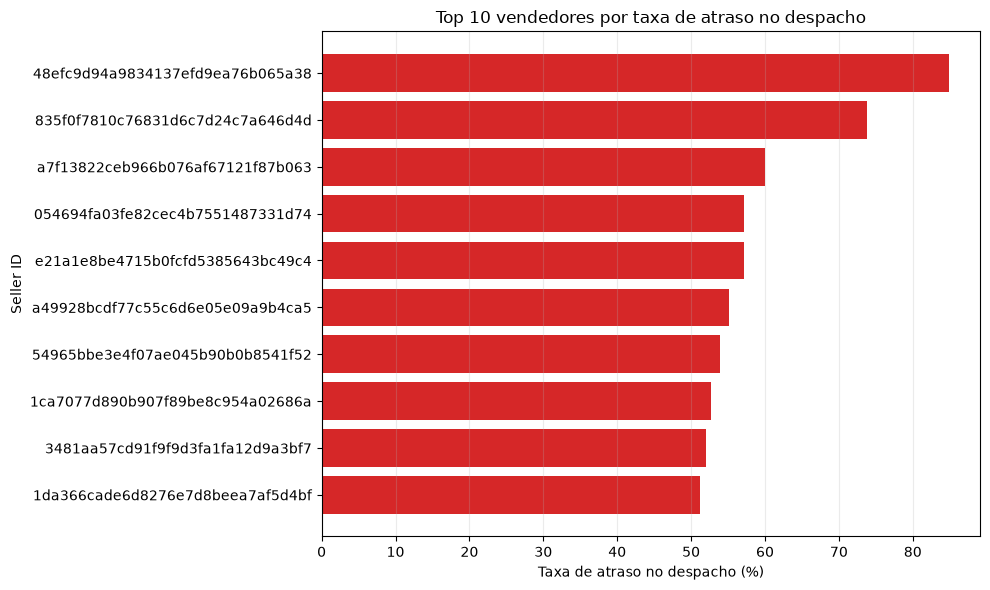

Taxa mediana de atraso dos vendedores elegíveis: 4.76 %
Maior taxa de atraso: 84.85 %


In [52]:
# [IA] registro 3

top_10_atrasos = ranking_atrasos.head(10).sort_values(
    "taxa_atraso_despacho_pct", ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_10_atrasos["seller_id"], top_10_atrasos["taxa_atraso_despacho_pct"], color="#d62728")
ax.set_title("Top 10 vendedores por taxa de atraso no despacho")
ax.set_xlabel("Taxa de atraso no despacho (%)")
ax.set_ylabel("Seller ID")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print("Taxa mediana de atraso dos vendedores elegíveis:",
      round(ranking_atrasos["taxa_atraso_despacho_pct"].median(), 2), "%")
print("Maior taxa de atraso:",
      round(ranking_atrasos["taxa_atraso_despacho_pct"].max(), 2), "%")


In [53]:
pedidos_com_atraso = tabela_pipeline.loc[
    tabela_pipeline["flag_atraso_despacho"] == True,
    ["seller_id", "order_id", "nota_media_pedido", "atraso_despacho_dias"]
].copy()

pedidos_sem_atraso = tabela_pipeline.loc[
    tabela_pipeline["flag_atraso_despacho"] == False,
    ["seller_id", "order_id", "nota_media_pedido", "atraso_despacho_dias"]
].copy()

pedidos_com_atraso_avaliados = pedidos_com_atraso.dropna(subset=["nota_media_pedido"])
pedidos_sem_atraso_avaliados = pedidos_sem_atraso.dropna(subset=["nota_media_pedido"])

comparacao_atraso_nota = pd.DataFrame({
    "situacao": ["Com atraso no despacho", "Sem atraso no despacho"],
    "qtd_pedidos": [len(pedidos_com_atraso_avaliados), len(pedidos_sem_atraso_avaliados)],
    "nota_media": [pedidos_com_atraso_avaliados["nota_media_pedido"].mean(),
                    pedidos_sem_atraso_avaliados["nota_media_pedido"].mean()],
    "taxa_nota_baixa_pct": [
        100 * pedidos_com_atraso_avaliados["nota_media_pedido"].le(2).mean(),
        100 * pedidos_sem_atraso_avaliados["nota_media_pedido"].le(2).mean(),
    ],
})

display(comparacao_atraso_nota)


,situacao,qtd_pedidos,nota_media,taxa_nota_baixa_pct
0,Com atraso no despacho,8793,3.670022,24.496759
1,Sem atraso no despacho,89222,4.159116,12.799534


## Pergunta 2 — Vendedores que atrasam recebem avaliações piores?

Comparamos pedidos com atraso no despacho e pedidos sem atraso no conjunto de pedidos com dados suficientes.

A tabela apresenta a quantidade de pedidos avaliados, a nota média e a porcentagem de pedidos com média menor ou igual a 2.

Esse resultado mostra associação entre atraso e avaliação, mas não prova que o atraso tenha causado diretamente a nota baixa.


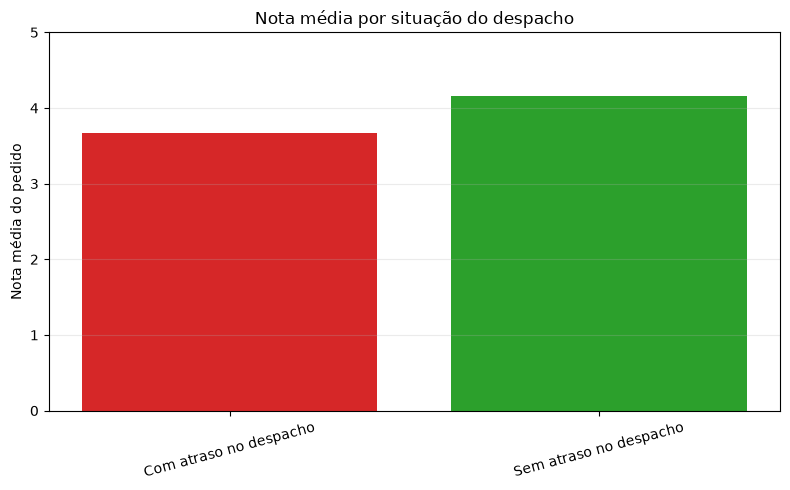

Vendedores considerados na comparação: 1269


,seller_id,seller_state,qtd_pedidos,pedidos_despacho_avaliavel,pedidos_com_atraso_despacho,taxa_atraso_despacho_pct,nota_media,pedidos_nota_baixa,taxa_nota_baixa_pct,risco_atraso_nota
1847,973f21788dfab357250f69a8dcb7ddee,MG,10,9,8,88.888889,2.000000,7,70.0,158.888889
809,4342d4b2ba6b161468c63a7e7cfce593,RJ,20,2,1,50.0,1.263158,18,94.736842,144.736842
2136,b1b3948701c5c72445495bd161b83a4c,SP,18,15,10,66.666667,1.722222,14,77.777778,144.444444
32,02d35243ea2e497335cd0f076b45675d,RN,14,14,12,85.714286,2.642857,6,42.857143,128.571429
320,1b8b75e227c9a9c100d0c210fb6176ce,SP,19,17,14,82.352941,3.368421,7,36.842105,119.195046
2862,ecccfa2bb93b34a3bf033cc5d1dcdc69,PR,15,14,9,64.285714,2.571429,7,50.0,114.285714
333,1ca7077d890b907f89be8c954a02686a,SP,115,114,60,52.631579,2.333333,70,61.403509,114.035088
2132,b19f3ca2ea475913750f25a5c37c8d8f,MG,24,19,11,57.894737,2.791667,12,50.0,107.894737
1614,835f0f7810c76831d6c7d24c7a646d4d,SP,44,42,31,73.809524,3.340909,14,31.818182,105.627706
774,40db9e9aa57f7bb151bcda6b0f9bdbb7,PE,12,12,5,41.666667,2.363636,7,63.636364,105.30303


In [54]:
# [IA] registro 3

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(comparacao_atraso_nota["situacao"], comparacao_atraso_nota["nota_media"], color=["#d62728", "#2ca02c"])
ax.set_title("Nota média por situação do despacho")
ax.set_ylabel("Nota média do pedido")
ax.set_ylim(0, 5)
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

vendedores_com_nota = indicadores_vendedores.loc[
    indicadores_vendedores["pedidos_com_nota"] >= MIN_PEDIDOS_AVALIADOS,
    ["seller_id", "seller_state", "qtd_pedidos", "pedidos_despacho_avaliavel",
     "pedidos_com_atraso_despacho", "taxa_atraso_despacho_pct",
     "nota_media", "pedidos_nota_baixa", "taxa_nota_baixa_pct"],
].copy()

vendedores_com_nota["risco_atraso_nota"] = (
    vendedores_com_nota["taxa_atraso_despacho_pct"]
    + vendedores_com_nota["taxa_nota_baixa_pct"]
)

vendedores_com_nota = vendedores_com_nota.sort_values("risco_atraso_nota", ascending=False)
print("Vendedores considerados na comparação:", len(vendedores_com_nota))
display(vendedores_com_nota.head(10))


## Pergunta 3 — Que critérios objetivos a empresa poderia usar para acompanhar ou advertir vendedores?

Podemos determinar o nível dos vendedores pelos seguintes indicativos:

- Mínimo de 20 pedidos avaliáveis no despacho.
- Mínimo de 10 pedidos com avaliação.
- Taxa de atraso no despacho igual ou superior a 20%.
- Taxa de pedidos com média menor ou igual a 2 igual ou superior a 20%.

Acompanhar ou advertir?

- **Advertência**: atraso maior ou igual a 20% ou avaliações baixas em pelo menos 20% dos pedidos.
- **Revisão prioritária**: os dois critérios estão acima do limite.
- **Acompanhamento regular**: os dois critérios estão abaixo do limite.


In [55]:
# [IA] registro 3

CRITERIO_ATRASO_PCT = 20
CRITERIO_NOTA_BAIXA_PCT = 20

acompanhamento = indicadores_vendedores.loc[
    (indicadores_vendedores["pedidos_despacho_avaliavel"] >= MIN_PEDIDOS_DESPACHO)
    & (indicadores_vendedores["pedidos_com_nota"] >= MIN_PEDIDOS_AVALIADOS),
    ["seller_id", "seller_state", "qtd_pedidos",
     "pedidos_despacho_avaliavel", "taxa_atraso_despacho_pct",
     "pedidos_com_nota", "nota_media", "taxa_nota_baixa_pct"],
].copy()

atraso_alto = acompanhamento["taxa_atraso_despacho_pct"] >= CRITERIO_ATRASO_PCT
nota_baixa_alta = acompanhamento["taxa_nota_baixa_pct"] >= CRITERIO_NOTA_BAIXA_PCT

acompanhamento["classificacao"] = "Acompanhamento regular"
acompanhamento.loc[atraso_alto | nota_baixa_alta, "classificacao"] = "Advertência"
acompanhamento.loc[atraso_alto & nota_baixa_alta, "classificacao"] = "Revisão prioritária"

acompanhamento = acompanhamento.sort_values(
    ["classificacao", "taxa_atraso_despacho_pct", "taxa_nota_baixa_pct"],
    ascending=[True, False, False],
)

print("Distribuição das classificações:")
display(acompanhamento["classificacao"].value_counts())
display(acompanhamento.head(15))

# Salva automaticamente as tabelas produzidas.
from pathlib import Path

PASTA_TABELAS_ANALITICAS = PASTA_PROJETO / "tabelas_analiticas"
PASTA_TABELAS_ANALITICAS.mkdir(parents=True, exist_ok=True)

arquivos_etapa6 = {
    "ranking_vendedores_atrasos.csv": ranking_atrasos,
    "comparacao_atraso_avaliacao.csv": comparacao_atraso_nota,
    "acompanhamento_vendedores.csv": acompanhamento,
}

for nome_arquivo, tabela in arquivos_etapa6.items():
    caminho_arquivo = PASTA_TABELAS_ANALITICAS / nome_arquivo
    tabela.to_csv(caminho_arquivo, index=False, encoding="utf-8-sig")
    print(f"{nome_arquivo}: {len(tabela):,} linhas — {caminho_arquivo}")


Distribuição das classificações:


classificacao
Acompanhamento regular    591
Advertência               172
Revisão prioritária        48
Name: count, dtype: int64

,seller_id,seller_state,qtd_pedidos,pedidos_despacho_avaliavel,taxa_atraso_despacho_pct,pedidos_com_nota,nota_media,taxa_nota_baixa_pct,classificacao
2935,f27e33c6d29b5138fa9967bcd445b6d5,SP,93,93,19.354839,93,4.096774,16.129032,Acompanhamento regular
866,4917cee8d902e13428c3ec4b1ca6f315,SC,33,31,19.354839,32,4.156250,12.5,Acompanhamento regular
2989,f7496d659ca9fdaf323c0aae84176632,SP,26,26,19.230769,26,4.576923,7.692308,Acompanhamento regular
2151,b32be1695eb7ec5f10f72d9610a12527,RS,45,44,18.181818,44,4.068182,13.636364,Acompanhamento regular
1056,5670f4db5b62c43d542e1b2d56b0cf7c,SP,22,22,18.181818,22,4.409091,9.090909,Acompanhamento regular
2170,b499c00f28f4b7069ff6550af8c1348a,SP,152,150,18.0,152,4.125000,13.157895,Acompanhamento regular
2766,e5a3438891c0bfdb9394643f95273d8e,SP,224,223,17.93722,222,3.927928,18.918919,Acompanhamento regular
1916,9d5a9018aee56acb367ba9c3f05d1d6a,GO,67,67,17.910448,67,4.417910,11.940299,Acompanhamento regular
192,1025f0e2d44d7041d6cf58b6550e0bfa,SP,915,914,17.724289,907,3.992282,17.199559,Acompanhamento regular
2586,d5ba419e26d246a0719437cf37d9b46d,SP,34,34,17.647059,33,3.909091,18.181818,Acompanhamento regular


ranking_vendedores_atrasos.csv: 811 linhas — C:\Users\r0663\OneDrive\Documentos\GitHub\Projeto-Analise-Exploratoria-Olist-Vendedores\tabelas_analiticas\ranking_vendedores_atrasos.csv
comparacao_atraso_avaliacao.csv: 2 linhas — C:\Users\r0663\OneDrive\Documentos\GitHub\Projeto-Analise-Exploratoria-Olist-Vendedores\tabelas_analiticas\comparacao_atraso_avaliacao.csv
acompanhamento_vendedores.csv: 811 linhas — C:\Users\r0663\OneDrive\Documentos\GitHub\Projeto-Analise-Exploratoria-Olist-Vendedores\tabelas_analiticas\acompanhamento_vendedores.csv
